# 03 · LightGBM

**Goal:** train a global machine learning model (a single model for the 600 series) and check whether it beats the best simple model from notebook 02, which is the reference: **SES + weekly index** (RMSSE of 0.742 in validation and 0.769 in test; MAE of 1.036 and 1.008).

**Why LightGBM:** it is a gradient-boosted tree model, fast on CPU, that handles variables of different types and missing values well, and it is the approach with which the best results were obtained in the M5 competition.

**Direct strategy:** instead of forecasting one day and using that forecast for the next (recursive strategy, which accumulates errors), **a single model** is trained that predicts the sales of any day in the horizon. Each row of the training set represents a series, an origin (the day from which the forecast is made), and a day of the horizon (from 1 to 28 days ahead); the `horizon` variable tells the model how far away the day to be predicted is.

**Protocol (the one from notebook 01):**
- The hyperparameters are chosen on the **validation window**, training only with data prior to its origin.
- The chosen model is **retrained** with the data up to the test origin and evaluated on the test **only once**.
- Metrics: RMSSE and MAE.

## 1. Setup and data

In [1]:
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

from src.data import ensure_m5, load_calendar, load_prices, load_sales, day_columns, sample_series, SEED
from src.metrics import evaluar, rmsse
from src.forecasting import (
    ventanas, clasificar_demanda, guardar_resultados,
    pronostico_media_movil, ses_semanal,
)
from src.gbm import (
    HORIZONTE, preparar_contexto, construir_dataset, construir_varios, a_matriz,
    verificar_sin_fuga, entrenar, reentrenar,
)

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 40)

In [2]:
carpeta = ensure_m5()
calendario = load_calendar(carpeta)
precios = load_prices(carpeta)
ventas = load_sales(carpeta)
dias = day_columns(ventas)

muestra = sample_series(ventas, n_per_store=60, seed=SEED)
ctx = preparar_contexto(muestra, calendario, precios, dias)

Y = ctx["Y"]
n, T = Y.shape
H = HORIZONTE
V = ventanas(T, H)
o_val = V["validation"][0] - 1   # origin of the validation window
o_test = V["test"][0] - 1        # origin of the test window
print(f"Series: {n} | days: {T} | validation origin: {o_val} | test origin: {o_test}")

Series: 600 | days: 1941 | validation origin: 1885 | test origin: 1913


## 2. Features

All the features in a row are known **at the origin** or were known in advance for the day to be forecast. Sales after the origin are never used.

| Group | Features | What they represent |
|---|---|---|
| Recent sales | `lag_0` to `lag_6` | Sales for each of the last 7 days (`lag_0` is the origin day) |
| Levels | `media_7`, `media_14`, `media_28`, `media_56`, `media_91`, `tendencia` | Average sales over different windows and the ratio between `media_28` and `media_91` |
| Intermittency | `desvio_28`, `ceros_28`, `ceros_91`, `dias_desde_venta`, `media_con_venta_91` | Variability, proportion of days with no sales, days since the last sale, and average sales on days with sales |
| Age | `edad` | Days since the first sale of the series |
| Same day of the week | `lag_mismo_dia`, `prom_mismo_dia_4s` | Sales on the same day of the previous week and the average of the last 4 weeks, for each day of the horizon |
| Horizon | `horizonte` | How many days ahead the day to be forecast is (1 to 28) |
| Calendar of the day to be forecast | `dia_semana`, `dia_mes`, `mes`, `es_navidad`, `tipo_evento`, `snap` | Day of the week and of the month, month, December 25 flag, event type, and whether it is a SNAP day in the store's state |
| Price of the day to be forecast | `precio_obj`, `precio_rel_origen`, `precio_rel_mediana` | Price, and relative to the price at the origin and to the series' historical median. As in the protocol, future prices are assumed to be known |
| Series | `tienda`, `departamento`, `categoria` | Categorical features |

**Anti-leakage test:** the sales after the origin are randomly altered and it is verified that the features do not change. It is the most important check in this type of pipeline, because an indexing error that "looks into the future" would make the model look excellent in the evaluation and fail in practice.

In [3]:
print("The features do not change when the sales after the origin are altered:", verificar_sin_fuga(ctx, o_val))

X_demo, y_demo, idx_demo = construir_dataset(ctx, o_val)
print(f"Rows in the set for one origin: {len(X_demo):,} = {len(idx_demo)} series × {H} days")
X_demo.head(3)

The features do not change when the sales after the origin are altered: True
Rows in the set for one origin: 16,800 = 600 series × 28 days


,lag_0,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,media_7,media_14,media_28,media_56,media_91,desvio_28,ceros_28,ceros_91,dias_desde_venta,media_con_venta_91,tendencia,edad,lag_mismo_dia,prom_mismo_dia_4s,horizonte,dia_semana,dia_mes,mes,es_navidad,tipo_evento,snap,precio_obj,precio_rel_origen,precio_rel_mediana,tienda,departamento,categoria
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,190.0,NaN,0.0,1436.0,0.0,0.0,1,2,28,3,0,ninguno,0,5.88,1.0,1.0,CA_1,HOBBIES_1,HOBBIES
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,190.0,NaN,0.0,1436.0,0.0,0.0,2,3,29,3,0,ninguno,0,5.88,1.0,1.0,CA_1,HOBBIES_1,HOBBIES
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,190.0,NaN,0.0,1436.0,0.0,0.0,3,4,30,3,0,ninguno,0,5.88,1.0,1.0,CA_1,HOBBIES_1,HOBBIES


## 3. Training sets

The training origins are **weekly and fall on the same day of the week as the origin being evaluated**, as happens with the validation and test origins (they are 28 days apart). The last `N_ORIGENES` origins are used (52 is equivalent to one year), because sales grow over time and recent data describes current demand better.

So that the model does not see the future, the days to be predicted from any training origin end before the evaluation origin:
- **Validation:** origins up to day `o_val − 28`.
- **Test:** origins up to day `o_test − 28` (which include the data from the validation window).

**Early stopping** (stopping adding trees when the error stops improving) needs a holdout set. The 4 most recent training origins are reserved for that, which are not used for training at the validation stage. The validation window is not used for that, so that its metrics are an honest measure of performance.

In [4]:
N_ORIGENES = 52   # weekly training origins (≈ 1 year)
PASO = 7
N_CONTROL = 4     # most recent origins reserved as the early stopping holdout

orig_val = [o_val - H - PASO * j for j in range(N_ORIGENES)]     # from most recent to oldest
orig_test = [o_test - H - PASO * j for j in range(N_ORIGENES)]

t0 = time.time()
X_ctrl, y_ctrl = construir_varios(ctx, orig_val[:N_CONTROL])
X_tr, y_tr = construir_varios(ctx, orig_val[N_CONTROL:])
print(f"Train: {len(X_tr):,} rows | control: {len(X_ctrl):,} rows | {time.time() - t0:.0f} s")
print(f"Training origins: day {orig_val[-1]} to {orig_val[N_CONTROL]} | control: day {orig_val[N_CONTROL - 1]} to {orig_val[0]}")

Train: 800,212 rows | control: 67,172 rows | 2 s
Training origins: day 1500 to 1829 | control: day 1836 to 1857


## 4. Choosing the objective and the hyperparameters (on validation)

**Objective (loss function).** With daily sales that are zero most of the time and positive values the rest of the time, the **Tweedie** loss (with an exponent between 1 and 2) usually fits better than squared error: with an exponent close to 1 it resembles Poisson (counts) and with one close to 2, Gamma (continuous positive values). Three exponents are tested, with squared error as a reference.

**Complexity.** With the best objective, the number of leaves per tree (15, 31, and 63) is tested, which controls how much each tree can fit the data.

The selection criterion is the **RMSSE of the validation window**; the MAE is reported alongside it. The number of trees of each model is defined by early stopping.

**Expected warning:** with the installed version of LightGBM, each training run shows a warning (`LGBMDeprecationWarning`) because the `eval_set` argument is deprecated and was replaced by `eval_X` and `eval_y`. It is only a notice and does not affect the results.

In [5]:
def predecir(modelo, origen):
    X, _, idx = construir_dataset(ctx, origen, con_objetivo=False)
    return a_matriz(modelo.predict(X), idx, n)

Y_train_val = Y[:, :o_val]
Y_real_val = Y[:, o_val:o_val + H]

def correr(nombre, config):
    t0 = time.time()
    modelo = entrenar(X_tr, y_tr, X_ctrl, y_ctrl, config)
    arboles = modelo.best_iteration_ if modelo.best_iteration_ else modelo.n_estimators
    pred = predecir(modelo, o_val)
    m = evaluar(Y_train_val, Y_real_val, pred)
    fila = {"config": nombre, "leaves": config["num_leaves"], "trees": int(arboles),
            "RMSSE": m["RMSSE"], "MAE": m["MAE"], "minutes": (time.time() - t0) / 60}
    print(f"{nombre:<28} trees {fila['trees']:>5} | RMSSE {fila['RMSSE']:.3f} | MAE {fila['MAE']:.3f} | {fila['minutes']:.1f} min")
    return modelo, pred, fila

CONFIGS = {
    "Tweedie 1,1": {"objective": "tweedie", "tweedie_variance_power": 1.1, "num_leaves": 31},
    "Tweedie 1,3": {"objective": "tweedie", "tweedie_variance_power": 1.3, "num_leaves": 31},
    "Tweedie 1,5": {"objective": "tweedie", "tweedie_variance_power": 1.5, "num_leaves": 31},
    "Squared error": {"objective": "regression", "num_leaves": 31},
}

modelos, preds_val, filas = {}, {}, []
for nombre, cfg in CONFIGS.items():
    modelos[nombre], preds_val[nombre], fila = correr(nombre, cfg)
    filas.append(fila)

c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Tweedie 1,1                  trees   446 | RMSSE 0.745 | MAE 0.995 | 0.1 min


c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Tweedie 1,3                  trees   578 | RMSSE 0.742 | MAE 0.984 | 0.2 min


c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Tweedie 1,5                  trees   403 | RMSSE 0.741 | MAE 0.980 | 0.1 min


c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Squared error                trees    97 | RMSSE 0.750 | MAE 1.010 | 0.0 min


In [6]:
tabla_obj = pd.DataFrame(filas).set_index("config")[["trees", "RMSSE", "MAE", "minutes"]]
mejor_obj = tabla_obj["RMSSE"].idxmin()
print("Best objective on validation (RMSSE):", mejor_obj)
tabla_obj.round(3)

Best objective on validation (RMSSE): Tweedie 1,5


,trees,RMSSE,MAE,minutes
config,,,,
"Tweedie 1,1",446,0.745,0.995,0.147
"Tweedie 1,3",578,0.742,0.984,0.160
"Tweedie 1,5",403,0.741,0.980,0.124
Squared error,97,0.750,1.010,0.047


In [7]:
base = CONFIGS[mejor_obj]
for hojas in (15, 63):
    nombre = f"{mejor_obj}, {hojas} leaves"
    CONFIGS[nombre] = {**base, "num_leaves": hojas}
    modelos[nombre], preds_val[nombre], fila = correr(nombre, CONFIGS[nombre])
    filas.append(fila)

tabla_exp = pd.DataFrame(filas).set_index("config")[["leaves", "trees", "RMSSE", "MAE", "minutes"]]
mejor = tabla_exp["RMSSE"].idxmin()
print("Chosen configuration (lowest RMSSE on validation):", mejor)
tabla_exp.sort_values("RMSSE").round(3)

c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Tweedie 1,5, 15 leaves       trees   509 | RMSSE 0.740 | MAE 0.983 | 0.1 min


c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Tweedie 1,5, 63 leaves       trees   311 | RMSSE 0.741 | MAE 0.983 | 0.1 min
Chosen configuration (lowest RMSSE on validation): Tweedie 1,5, 15 leaves


,leaves,trees,RMSSE,MAE,minutes
config,,,,,
"Tweedie 1,5, 15 leaves",15,509,0.740,0.983,0.132
"Tweedie 1,5",31,403,0.741,0.980,0.124
"Tweedie 1,5, 63 leaves",63,311,0.741,0.983,0.121
"Tweedie 1,3",31,578,0.742,0.984,0.160
"Tweedie 1,1",31,446,0.745,0.995,0.147
Squared error,31,97,0.750,1.010,0.047


### 4.1 Comparison with the simple models on validation

The best configuration is compared with the models from notebook 02 on the same window.

In [8]:
ruta = os.path.join(ROOT, "reports", "resultados_modelos.csv")
previos = pd.read_csv(ruta) if os.path.exists(ruta) else pd.DataFrame()
ref = previos[(previos["window"] == "validation") & (previos["model"] != "LightGBM")].set_index("model")[["RMSSE", "MAE"]] if len(previos) else pd.DataFrame()

comp = pd.concat([ref, pd.DataFrame({"RMSSE": [tabla_exp.loc[mejor, "RMSSE"]], "MAE": [tabla_exp.loc[mejor, "MAE"]]}, index=["LightGBM"])])
comp.sort_values("RMSSE").round(3)

,RMSSE,MAE
LightGBM,0.740,0.983
SES + weekly index,0.742,1.036
28-day moving average,0.751,1.020
Seasonal average (4 weeks),0.811,1.045
Naive,0.936,1.361
Zero,0.940,1.392
Seasonal naive,0.995,1.195


## 5. Final model and evaluation on test

With the chosen configuration and the number of trees decided by early stopping on validation, the model is **retrained** with the origins up to `o_test − 28`, which include the data from the validation window. It is then evaluated on the test, **only once**.

In [9]:
config_final = CONFIGS[mejor]
arboles_final = int(tabla_exp.loc[mejor, "trees"])

t0 = time.time()
X_fin, y_fin = construir_varios(ctx, orig_test)
modelo_final = reentrenar(X_fin, y_fin, config_final, arboles_final)
print(f"Retrained with {len(X_fin):,} rows and {arboles_final} trees in {(time.time() - t0) / 60:.1f} min")

Y_train_test = Y[:, :o_test]
Y_real_test = Y[:, o_test:o_test + H]
pred_test = predecir(modelo_final, o_test)
m_test = evaluar(Y_train_test, Y_real_test, pred_test)
m_val = evaluar(Y_train_val, Y_real_val, preds_val[mejor])
print(f"Validation -> RMSSE {m_val['RMSSE']:.3f} | MAE {m_val['MAE']:.3f}")
print(f"Test       -> RMSSE {m_test['RMSSE']:.3f} | MAE {m_test['MAE']:.3f}")

Retrained with 868,588 rows and 509 trees in 0.1 min
Validation -> RMSSE 0.740 | MAE 0.983
Test       -> RMSSE 0.768 | MAE 1.011


In [10]:
resultado_lgbm = pd.DataFrame([
    {"model": "LightGBM", "window": "validation", **m_val},
    {"model": "LightGBM", "window": "test", **m_test},
])
acumulado = guardar_resultados(resultado_lgbm, ruta)

tabla = acumulado.pivot(index="model", columns="window", values=["RMSSE", "MAE"])
tabla = tabla[[("RMSSE", "validation"), ("RMSSE", "test"), ("MAE", "validation"), ("MAE", "test")]]
tabla.sort_values(("RMSSE", "validation")).round(3)

RMSSE               MAE       
window                     validation   test validation   test
model                                                         
LightGBM                        0.740  0.768      0.983  1.011
SES + weekly index              0.742  0.769      1.036  1.008
28-day moving average           0.751  0.782      1.020  1.059
Seasonal average (4 weeks)      0.811  0.849      1.045  1.101
Naive                           0.936  1.007      1.361  1.306
Zero                            0.940  0.990      1.392  1.477
Seasonal naive                  0.995  1.029      1.195  1.233

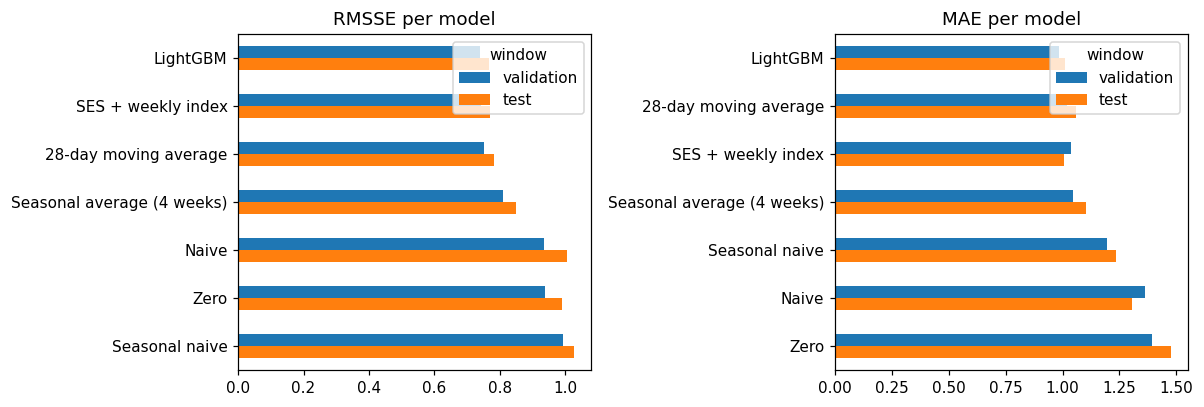

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metrica in zip(axes, ["RMSSE", "MAE"]):
    tabla[metrica].sort_values("validation").plot.barh(ax=ax)
    ax.set_title(metrica + " per model")
    ax.set_ylabel("")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 6. Model analysis

### 6.1 Which features it uses

Importance by **gain**: how much each feature reduces the error, summed across all trees, expressed as a proportion of the total. It shows what information the model uses, not that this feature *causes* the sales.

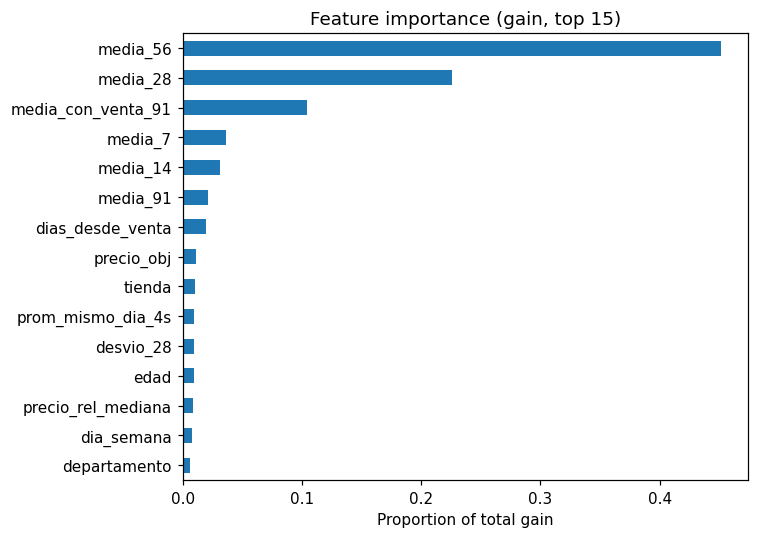

,importance
media_56,0.452
media_28,0.226
media_con_venta_91,0.105
media_7,0.036
media_14,0.031
media_91,0.021
dias_desde_venta,0.020
precio_obj,0.011
tienda,0.010
prom_mismo_dia_4s,0.009


In [12]:
imp = pd.Series(modelo_final.feature_importances_, index=X_fin.columns)
imp = (imp / imp.sum()).sort_values(ascending=False)

ax = imp.head(15).iloc[::-1].plot.barh(figsize=(7, 5))
ax.set_title("Feature importance (gain, top 15)")
ax.set_xlabel("Proportion of total gain")
plt.tight_layout()
plt.show()

imp.head(15).round(3).to_frame("importance")

### 6.2 Results by demand type (validation)

The series are classified with the history prior to the origin. LightGBM is compared with the moving average and with the statistical model from notebook 02.

In [13]:
wday = calendario["wday"].to_numpy() - 1
categorias = muestra["cat_id"].astype(str).to_numpy()
pred_ma = pronostico_media_movil(Y_train_val, H)
pred_ses = ses_semanal(Y_train_val, H, wday[:o_val], wday[o_val:o_val + H], categorias)[0]

tipo = clasificar_demanda(Y_train_val)["type"].to_numpy()
modelos_tipo = {"28-day moving average": pred_ma, "SES + weekly index": pred_ses, "LightGBM": preds_val[mejor]}
filas_t = []
for nombre, p in modelos_tipo.items():
    r = rmsse(Y_train_val, Y_real_val, p)
    a = np.abs(Y_real_val - p).mean(axis=1)
    g = pd.DataFrame({"type": tipo, "RMSSE": r, "MAE": a}).groupby("type").agg(RMSSE=("RMSSE", "mean"), MAE=("MAE", "mean"), series=("MAE", "size"))
    g["model"] = nombre
    filas_t.append(g.reset_index())
por_tipo = pd.concat(filas_t, ignore_index=True)

print("Series per type:", por_tipo.groupby("type")["series"].first().to_dict())
print()
print("RMSSE by demand type:")
por_tipo.pivot(index="model", columns="type", values="RMSSE").round(3)

Series per type: {'erratic': 19, 'intermittent': 434, 'irregular': 121, 'smooth': 26}

RMSSE by demand type:


type,erratic,intermittent,irregular,smooth
model,,,,
28-day moving average,0.912,0.765,0.688,0.689
LightGBM,0.805,0.757,0.688,0.651
SES + weekly index,0.877,0.756,0.686,0.668


In [14]:
print("MAE per type of demand:")
por_tipo.pivot(index="model", columns="type", values="MAE").round(3)

MAE per type of demand:


type,erratic,intermittent,irregular,smooth
model,,,,
28-day moving average,4.011,0.726,1.363,2.142
LightGBM,3.472,0.704,1.381,1.969
SES + weekly index,4.031,0.742,1.383,2.133


### 6.3 Error by day of the horizon

Average MAE for each day of the horizon (1 to 28 days after the origin), on the validation window. It shows whether the model loses accuracy as it moves away from the origin.

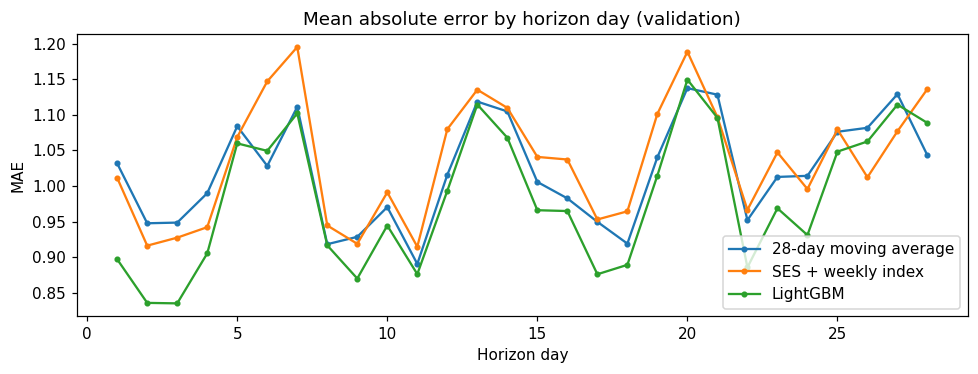

In [15]:
mae_k = {nombre: np.abs(Y_real_val - p).mean(axis=0) for nombre, p in modelos_tipo.items()}
fig, ax = plt.subplots(figsize=(9, 3.5))
for nombre, v in mae_k.items():
    ax.plot(np.arange(1, H + 1), v, marker="o", markersize=3, label=nombre)
ax.set_xlabel("Horizon day")
ax.set_ylabel("MAE")
ax.set_title("Mean absolute error by horizon day (validation)")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Save results

In [16]:
os.makedirs(os.path.join(ROOT, "models"), exist_ok=True)
os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)

modelo_final.booster_.save_model(os.path.join(ROOT, "models", "lightgbm_final.txt"))
tabla_exp.to_csv(os.path.join(ROOT, "reports", "lightgbm_experimentos.csv"))
np.savez(os.path.join(ROOT, "reports", "predicciones_lightgbm.npz"),
         validacion=preds_val[mejor], test=pred_test, ids=muestra["id"].astype(str).to_numpy().astype("U"))
print("Saved: model, experiments table and predictions")

Saved: model, experiments table and predictions


## 8. Conclusions

- **Leak-free pipeline:** the anti-leakage test returns `True`: the features do not change when the sales after the origin are altered. Each origin contributes 16,800 rows (600 series × 28 days) and the final model was trained with 868,588 rows. Each configuration took between 3 and 13 seconds, so compute was not a limitation.
- **Objective:** with Tweedie exponents of 1.1, 1.3, and 1.5, the RMSSE on validation is 0.745, 0.742, and 0.741 and the MAE is 0.995, 0.984, and 0.980. Squared error gives 0.750 and 1.010, and it stopped at only 97 trees. Tweedie improves on squared error by about 1% in RMSSE and 3% in MAE; among the three exponents the difference is less than 1%. The best is the highest of those tested (1.5), so it is not known whether higher values would improve it.
- **Complexity:** 15, 31, and 63 leaves per tree give an RMSSE of 0.740, 0.741, and 0.741 (509, 403, and 311 trees). The difference is irrelevant: the 15-leaf one was chosen because it has the lowest RMSSE, but any of the three would have been equivalent.
- **Comparison on validation:** LightGBM obtains an RMSSE of 0.740 and an MAE of 0.983, versus 0.742 and 1.036 for SES + weekly index and 0.751 and 1.020 for the moving average. The advantage in RMSSE over SES is 0.3%; in MAE, 5%. Since the configuration was chosen among six on this same window, these figures are somewhat optimistic.
- **Test (evaluated only once):** LightGBM obtains an RMSSE of 0.768 and an MAE of 1.011, versus 0.769 and 1.008 for SES: **a technical tie**. Compared with the moving average (0.782 and 1.059), the improvement is 1.8% in RMSSE and 4.5% in MAE. The MAE advantage over SES that existed on validation does not hold on test. In this sample there is no evidence that LightGBM beats the simple statistical model: differences of less than 1% cannot be distinguished from noise with a 28-day window and 600 series (notebook 04 quantifies this with confidence intervals).
- **Most used features:** `media_56` (45%), `media_28` (23%), and `media_con_venta_91` (11%) add up to 78% of the gain, and all the sales-level features together, about 87%. The model relies mainly on the recent level of sales, as the moving average does. The day of the week weighs 0.7%, the price of the day 1.1%, and the age of the series 0.9%; SNAP days, events, and the horizon are not among the top 15. Importance by gain does not measure causality, and with averages that are highly correlated with each other (`media_14`, `media_28`, `media_56`) the split among them is partly arbitrary.
- **By demand type (validation):** there are 19 erratic, 434 intermittent, 121 lumpy, and 26 smooth series. LightGBM has a lower RMSSE than SES in the erratic (0.805 versus 0.877) and smooth (0.651 versus 0.668) series, and ties in the intermittent (0.757 versus 0.756) and lumpy (0.688 versus 0.686). In MAE it improves in erratic (3.47 versus 4.03), smooth (1.97 versus 2.13), and intermittent (0.704 versus 0.742), and is slightly worse than the moving average in lumpy (1.381 versus 1.363). Of the total MAE improvement over SES on validation (0.053), about 52% comes from the intermittent series, 34% from the erratic, and 13% from the smooth. The erratic and smooth series are only 45 series, so those differences are unstable.
- **Error by horizon day (validation):** according to the chart, the MAE of the three models rises and falls in a similar way, with peaks and troughs on the same days and peaks 7 days apart, which reflects the weekly seasonality: the days with the most sales have larger absolute errors in units. LightGBM has the lowest error on almost every day, the moving average is in the middle, and SES is above both.
- **Interpretation (unverified hypothesis):** the daily demand of each product is very noisy, and a good part of the error would be irreducible; the recent level of sales and the weekly seasonality, which SES already captures, would explain almost everything that is predictable. Prices change in few weeks and the evaluation windows have few events, which limits the contribution of those features.
- **Limitations:** a single window per stage and no confidence intervals; 600 series out of 30,490; a configuration chosen among six, several with differences within the noise; Tweedie exponents greater than 1.5 and other hyperparameters (learning rate, regularization) were not explored; and the features were designed only once.
- **Next step:** notebook 04 trains a neural network in Keras and compares all the models, with bootstrap confidence intervals across series to quantify whether the differences are real.